In [1]:
import pandas as pd
import tables as tb
import matplotlib.pyplot as plt
import numpy as np
import glob as glob

from tqdm import tqdm
from scipy.spatial     import cKDTree
from scipy.optimize import curve_fit

In [2]:
path = '/data/pablovzqz/NEXT100-data/LightTables/NEXT100_MC_v07_11_00_May2026_S2_LT.h5'
psf_path = '/data/pablovzqz/NEXT100-data/LightTables/NEXT100_MC_v07_11_00_May2026_PSF_LT.h5' 

In [3]:
with tb.open_file(path, 'r') as h5file:
    data = h5file.root.LT.LightTable[:]
    lt = pd.DataFrame(data)

with tb.open_file(psf_path, 'r') as h5file:
    data = h5file.root.PSF.LightTable[:]
    psf = pd.DataFrame(data)


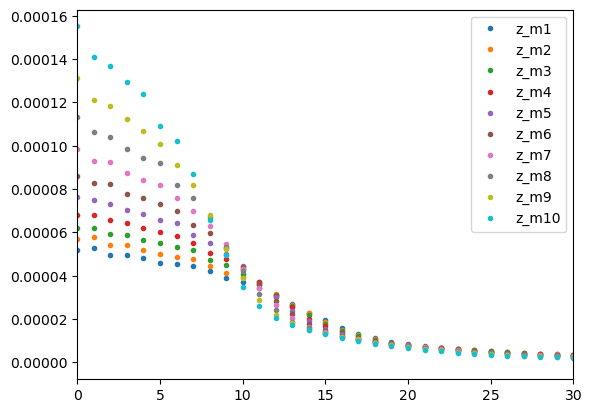

In [4]:
for c in psf.columns:
    if c != psf.columns[0]:
        plt.plot(psf[psf.columns[0]], psf[c], label=c, marker='o', markersize=3, linestyle='None')
        plt.legend()
        plt.xlim(0, 30)

In [5]:
light_map = pd.DataFrame({'x': lt['x'], 'y': lt['y'], 'factor': lt['PmtR11410_total']})

In [6]:
import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator

# Pivot to a 2D array on the regular grid
xs = np.sort(light_map['x'].unique())
ys = np.sort(light_map['y'].unique())
Z = (light_map.pivot(index='x', columns='y', values='factor')
              .reindex(index=xs, columns=ys)
              .values)

interp = RegularGridInterpolator((xs, ys), Z, method='linear',
                                 bounds_error=False, fill_value=None)

# New 15 mm grid, kept inside the original range
xn = np.arange(xs.min(), xs.max() + 1e-9, 15)
yn = np.arange(ys.min(), ys.max() + 1e-9, 15)
XN, YN = np.meshgrid(xn, yn, indexing='ij')

Zn = interp(np.column_stack([XN.ravel(), YN.ravel()]))

light_map= pd.DataFrame({'x': XN.ravel(), 'y': YN.ravel(), 'factor': Zn})

In [7]:
light_map = pd.DataFrame({'x': light_map['x'], 'y': light_map['y'], 'factor': light_map['factor']/light_map.factor.sum()})

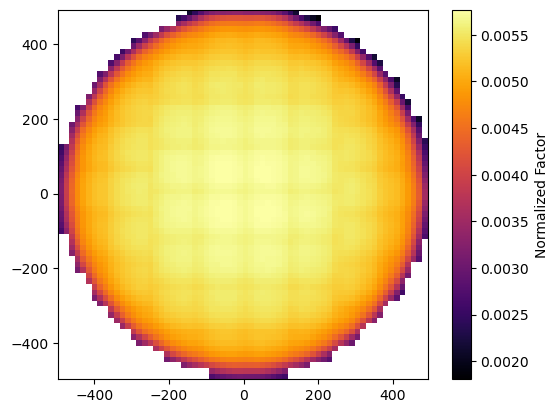

In [8]:
import matplotlib.pyplot as plt

# Opción 1: pcolormesh directo desde la malla interpolada
Zn_2d = Zn.reshape(XN.shape)
plt.pcolormesh(xn, yn, Zn_2d.T, shading='nearest', cmap='inferno')
plt.colorbar(label='Normalized Factor')
plt.gca().set_aspect('equal')

# Opción 2: si prefieres hist2d, bins centrados en cada punto
xe = np.append(xn - 7.5, xn[-1] + 7.5)
ye = np.append(yn - 7.5, yn[-1] + 7.5)
plt.hist2d(light_map.x, light_map.y, bins=[xe, ye],
           weights=light_map.factor, cmap='inferno');

In [9]:
lt_voxel_centers = np.column_stack([light_map.x.to_numpy(), light_map.y.to_numpy()])
tree_light_table = cKDTree(lt_voxel_centers)

In [10]:
## random_point = np.random.choice(lt_voxel_centers.flatten(), size=2)
## distance, bin_id = tree_light_table.query(random_point) devuelve el indicie de la light table mas cercano a ese punto

In [11]:
path = glob.glob(f"/data/pablovzqz/NEXT100-data/HE/hits_parts/*.h5")[0:1]

In [12]:
def load_hits(path):

    with tb.open_file(path, mode="r") as f:

        group = f.root.hits

        arrays = []
        columns = []

        i = 0
        while hasattr(group, f"block{i}_values"):

            values = getattr(group, f"block{i}_values")[:]
            items = getattr(group, f"block{i}_items")[:]

            names = [
                x.decode("utf-8") if isinstance(x, bytes) else x
                for x in items
            ]

            arrays.append(values)
            columns.extend(names)

            i += 1

        return pd.DataFrame(
            np.concatenate(arrays, axis=1),
            columns=columns
        )

dfs = []

for p in tqdm(path[0:15]):
    dfs.append(load_hits(p))

df = pd.concat(dfs, ignore_index=True)

del dfs


  0%|                                                                                                                                                                                      | 0/1 [00:00<?, ?it/s]

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:03<00:00,  3.76s/it]


In [13]:
ev = df[df["event"] == df["event"].unique()[0]]

In [14]:
ev_points = np.column_stack([ev.X.to_numpy(), ev.Y.to_numpy()])
distance, bin_id = tree_light_table.query(ev_points)

In [15]:
np.shape(light_map.factor.to_numpy())

(4356,)

In [16]:
H, xedges, yedges = np.histogram2d(
    ev["X"],
    ev["Y"],
    bins=66,
    weights=ev["E"] / ev["E"].sum(), range = ((-500, 500), (-500, 500))
)

centers_x = (xedges[:-1] + xedges[1:]) / 2
centers_y = (yedges[:-1] + yedges[1:]) / 2

In [17]:
y = H.ravel()

In [18]:
N_EVENTS = 1000_0000
R = 500          # mm       
Z = 230          # mm           
ENERGY = 0.0415  # MeV      
VOXEL_SIZE = 2   # mm

rng = np.random.default_rng(42)

# Genero un cuadrado de coordenadas y luego filtro los que están dentro del círculo de radio R
coords = np.arange(-np.ceil(R), np.ceil(R) + VOXEL_SIZE, VOXEL_SIZE)
X, Y = np.meshgrid(coords, coords, indexing="xy")

# Máscara boolean para filtrar los puntos dentro del círculo de radio R
inside = X**2 + Y**2 <= R**2
valid_positions = np.column_stack((X[inside], Y[inside]))

# -----------------------------
# Generar eventos
# -----------------------------
indices = rng.integers(0, len(valid_positions), size=N_EVENTS)
xy = valid_positions[indices]

df = pd.DataFrame({"event_id": np.arange(N_EVENTS), "x": xy[:, 0], "y": xy[:, 1], "z": np.full(N_EVENTS, Z), "energy": np.full(N_EVENTS, ENERGY)})

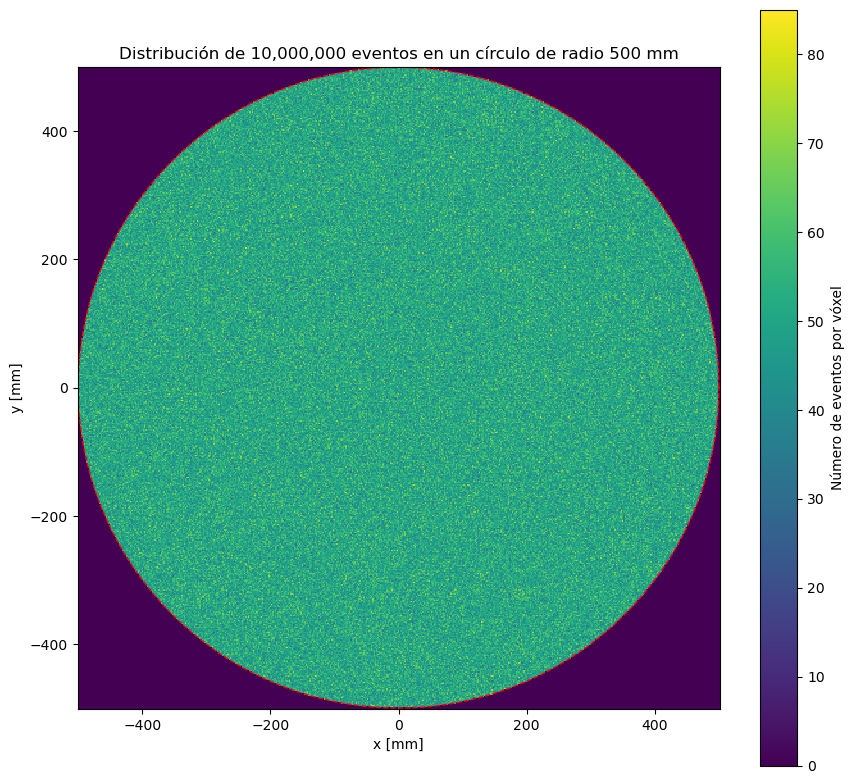

In [19]:
edges = np.arange(-np.ceil(R) - VOXEL_SIZE / 2, np.ceil(R) + 1.5 * VOXEL_SIZE, VOXEL_SIZE)
H, xedges, yedges = np.histogram2d(df["x"], df["y"], bins=[edges, edges])

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.pcolormesh(xedges, yedges, H.T, shading="auto", cmap="viridis")
fig.colorbar(im, ax=ax, label="Número de eventos por vóxel")
theta = np.linspace(0, 2 * np.pi, 500)
ax.plot(R * np.cos(theta), R * np.sin(theta), "r--", linewidth=1)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_title(f"Distribución de {N_EVENTS:,} eventos en un círculo de radio {R} mm")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [20]:
# Índices de los bins espaciales
df["x_bin"] = np.floor(df["x"] / VOXEL_SIZE).astype(int)
df["y_bin"] = np.floor(df["y"] / VOXEL_SIZE).astype(int)

# Identificador único para cada bin XY
df["bin_idx"] = pd.MultiIndex.from_arrays([df["x_bin"], df["y_bin"]]).factorize()[0]

# Centro espacial de cada bin
df["x_bin_center"] = (df["x_bin"] + 0.5) * VOXEL_SIZE
df["y_bin_center"] = (df["y_bin"] + 0.5) * VOXEL_SIZE

In [21]:
D, T, T0, Z_P, Z0_P, P, v_d = 4000/np.sqrt(4), 298.0, 293.0, 0.971, 0.961, 4.0, 0.88 

In [22]:
import sys
sys.path.insert(0, '/scratch/pablovzqz/MELT/src/')

from diffusion import D_from_D_star, sigma

In [23]:
drift_times = np.arange(0, 1400, 100)

In [24]:
sigma = sigma(D_from_D_star(D, T, T0, Z_P, Z0_P, P, v_d), drift_times)

In [25]:
D_from_D_star(D, T, T0, Z_P, Z0_P, 4, v_d) 

1808.66091564177

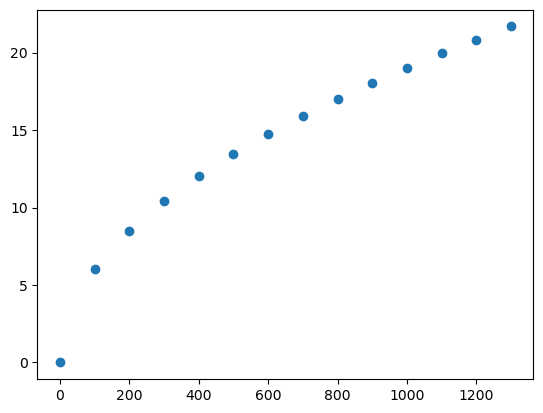

In [26]:
plt.plot(drift_times, sigma, 'o')

In [27]:
psf = 12 #mm

In [28]:
sigma = np.sqrt(sigma ** 2 + psf ** 2)

In [29]:
for i, s in enumerate(sigma):

    grouped_bins = df.groupby("bin_idx", sort=False)

    sensor_response_by_bin = []
    bin_ids = []
    bin_x = []
    bin_y = []
    n_electrons_by_bin = []

    for bin_idx, group in tqdm(grouped_bins):

        x0 = group["x"].to_numpy(dtype=float)
        y0 = group["y"].to_numpy(dtype=float)

        energy0 = group["energy"].to_numpy(dtype=float) * 1000

        # Número de electrones
        Nmean = energy0 * 1000 / 22.1

        N_diffuse = rng.normal(
            Nmean,
            np.sqrt(Nmean * 0.22)
        )

        # Gaussian smearing en XY
        x_smeared = x0 + rng.normal(0, s, size=len(x0))
        y_smeared = y0 + rng.normal(0, s, size=len(y0))

        # Histograma espacial
        H, _, _ = np.histogram2d(
            x_smeared,
            y_smeared,
            bins=66,
            range=((-500, 500), (-500, 500)),
            weights=N_diffuse
        )

        n_total = np.sum(N_diffuse)

        if H.sum() > 0 and n_total > 0:

            response = H.ravel() / H.sum()

            sensor_response_by_bin.append(response)
            bin_ids.append(bin_idx)

            bin_x.append(
                group["x_bin"].iloc[0] * VOXEL_SIZE + VOXEL_SIZE / 2
            )

            bin_y.append(
                group["y_bin"].iloc[0] * VOXEL_SIZE + VOXEL_SIZE / 2
            )

            n_electrons_by_bin.append(len(group))

    # Convertir a arrays NumPy
    sensor_response_by_bin = np.asarray(sensor_response_by_bin)
    bin_ids = np.asarray(bin_ids)
    bin_x = np.asarray(bin_x)
    bin_y = np.asarray(bin_y)
    n_electrons_by_bin = np.asarray(n_electrons_by_bin)

    print(f"\nSigma = {s:.2f}")
    print("Respuestas por bin:", sensor_response_by_bin.shape)
    print("Bins procesados:", len(bin_ids))

    # Guardar resultados
    np.save(f"/scratch/pablovzqz/MELT/data/sensor_response_by_bin_sigma_{int((i+1)*100)}.npy",
            sensor_response_by_bin)

    np.save(f"/scratch/pablovzqz/MELT/data/bin_ids_sigma_{int((i+1)*100)}.npy", bin_ids)
    np.save(f"/scratch/pablovzqz/MELT/data/bin_x_sigma_{int((i+1)*100)}.npy", bin_x)
    np.save(f"/scratch/pablovzqz/MELT/data/bin_y_sigma_{int((i+1)*100)}.npy", bin_y)
    np.save(f"/scratch/pablovzqz/MELT/data/n_electrons_by_bin_sigma_{int((i+1)*100)}.npy",
            n_electrons_by_bin)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 196321/196321 [01:28<00:00, 2208.79it/s]



Sigma = 12.00
Respuestas por bin: (196321, 4356)
Bins procesados: 196321


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 196321/196321 [01:25<00:00, 2291.96it/s]



Sigma = 13.42
Respuestas por bin: (196321, 4356)
Bins procesados: 196321


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 196321/196321 [01:24<00:00, 2317.19it/s]



Sigma = 14.71
Respuestas por bin: (196321, 4356)
Bins procesados: 196321


... (18 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 196321/196321 [01:27<00:00, 2248.99it/s]



Sigma = 24.04
Respuestas por bin: (196321, 4356)
Bins procesados: 196321


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 196321/196321 [01:25<00:00, 2287.89it/s]



Sigma = 24.78
Respuestas por bin: (196321, 4356)
Bins procesados: 196321


In [ ]:
initial_probability_distribution = np.ones(np.shape(sensor_response_by_bin)[0]) /np.shape(sensor_response_by_bin)[0]
guess = np.asarray(initial_probability_distribution, dtype=float).copy()

print("Integral de la distribución de probabilidad inicial:", np.sum(initial_probability_distribution))

Integral de la distribución de probabilidad inicial: 0.9999999999999993


In [ ]:
len(initial_probability_distribution)

196321

In [ ]:
P = np.asarray(sensor_response_by_bin, dtype=np.float64)
y = np.asarray(y, dtype=np.float64)

guess = np.ones(P.shape[0], dtype=np.float64)
guess /= guess.sum()

scale = guess @ P

In [ ]:
eps = 1e-15
n_iter = 100
guesses = []

guess = np.ones(P.shape[0], dtype=float)
guess /= guess.sum()

efficiency = P.sum(axis=1)

for i in tqdm(range(n_iter)):

    scale = guess @ P
    scale = np.maximum(scale, eps)

    correction = (y / scale) @ P.T

    guess *= correction / np.maximum(efficiency, eps)

    if i % 10 == 0:
        guesses.append(guess.copy())

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [02:21<00:00,  1.41s/it]


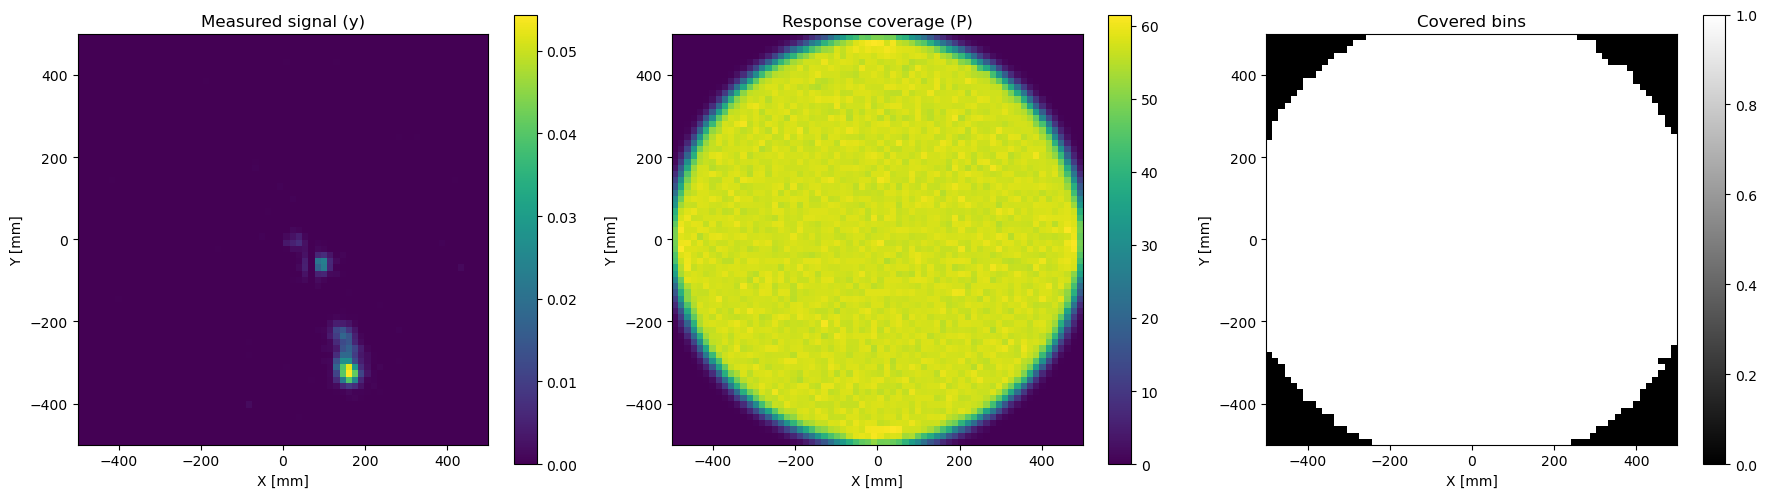

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

coverage = P.sum(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(
    y.reshape(66, 66).T,
    origin="lower",
    extent=(-500, 500, -500, 500)
)
axes[0].set_title("Measured signal (y)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(
    coverage.reshape(66, 66),
    origin="lower",
    extent=(-500, 500, -500, 500)
)
axes[1].set_title("Response coverage (P)")
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(
    (coverage > 0).reshape(66, 66),
    origin="lower",
    extent=(-500, 500, -500, 500),
    cmap="gray"
)
axes[2].set_title("Covered bins")
plt.colorbar(im2, ax=axes[2])

for ax in axes:
    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Y [mm]")

plt.tight_layout()
plt.show()

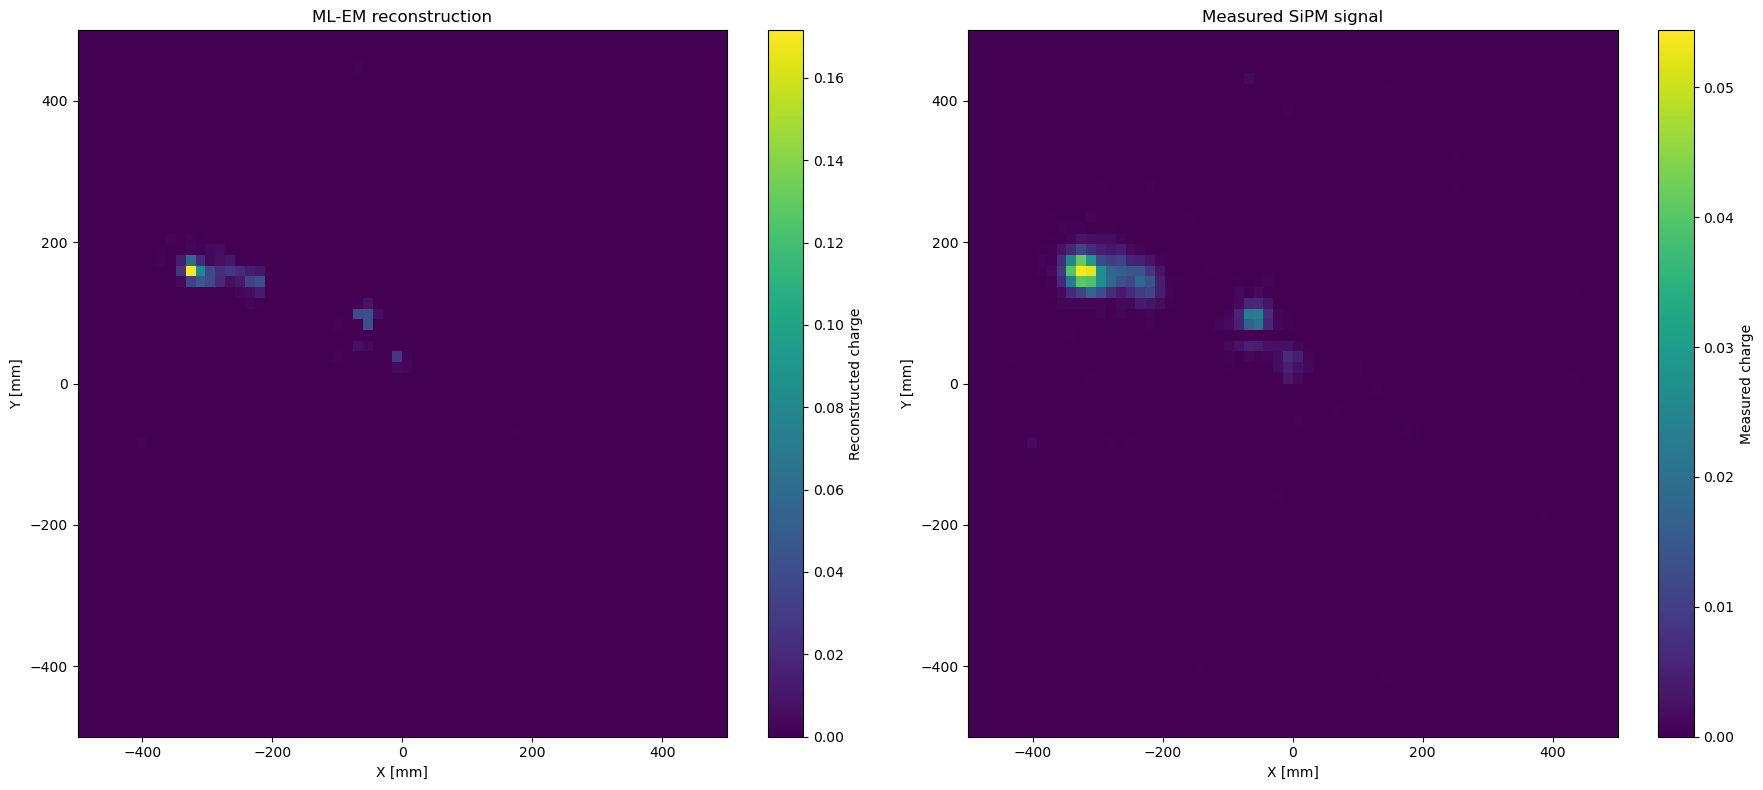

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# ============================================================
# 1. Reconstrucción ML-EM
# ============================================================

im0 = axes[0].hist2d(
    bin_x,
    bin_y,
    bins=66,
    weights=guess,
    range=((-500, 500), (-500, 500)),
    cmap="viridis"
)

axes[0].set_title("ML-EM reconstruction")
axes[0].set_xlabel("X [mm]")
axes[0].set_ylabel("Y [mm]")

plt.colorbar(im0[3], ax=axes[0], label="Reconstructed charge")


# ============================================================
# 2. Señal medida
# ============================================================

cmap = plt.get_cmap("viridis").copy()
cmap.set_under("white")

im1 = axes[1].imshow(
    y.reshape(66, 66).T,
    origin="lower",
    extent=(-500, 500, -500, 500),
    cmap=cmap,
    aspect="auto",
    vmax=y.max()
)

axes[1].set_title("Measured SiPM signal")
axes[1].set_xlabel("X [mm]")
axes[1].set_ylabel("Y [mm]")

plt.colorbar(im1, ax=axes[1], label="Measured charge")


# ============================================================
# 3. Configuración
# ============================================================

plt.tight_layout()
plt.show()

Sum of guess: 1.000000, NaN count: 0, Max value: 6.815517e-04


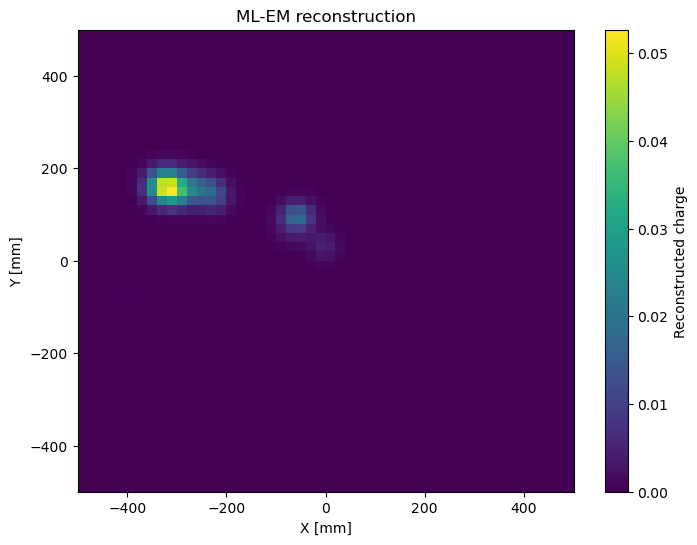

Sum of guess: 1.000000, NaN count: 0, Max value: 6.143817e-03


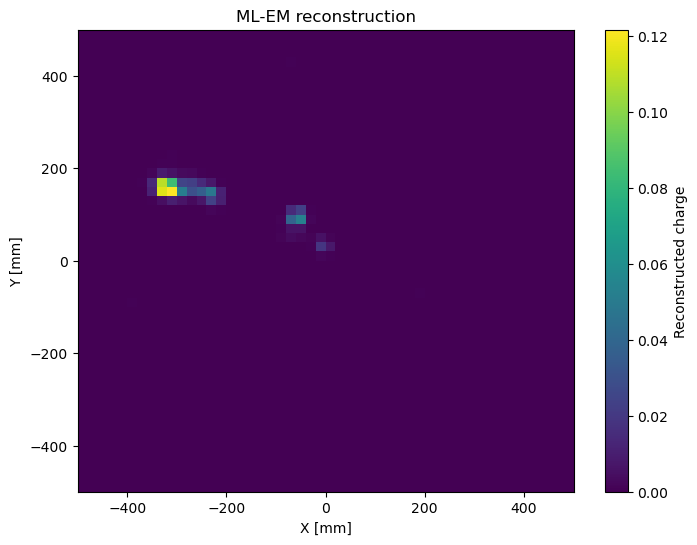

Sum of guess: 1.000000, NaN count: 0, Max value: 1.981336e-02


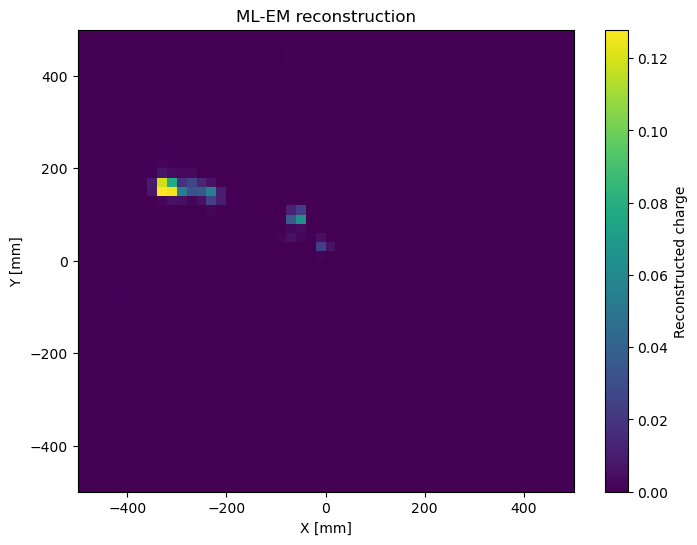

Sum of guess: 1.000000, NaN count: 0, Max value: 3.148289e-02


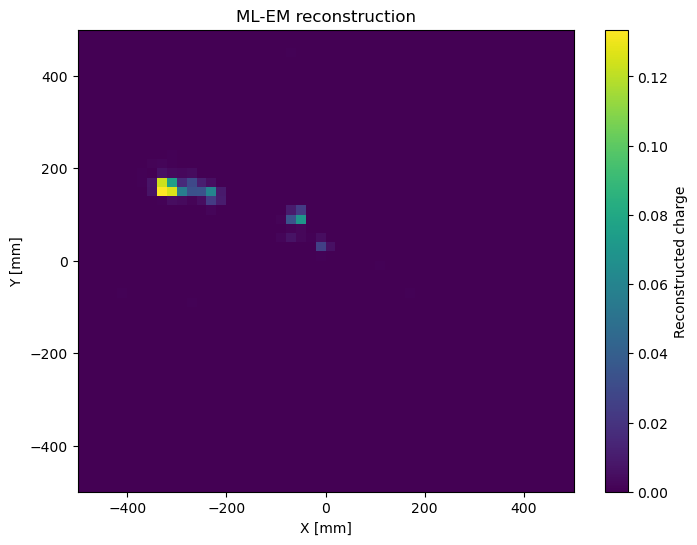

Sum of guess: 1.000000, NaN count: 0, Max value: 3.692679e-02


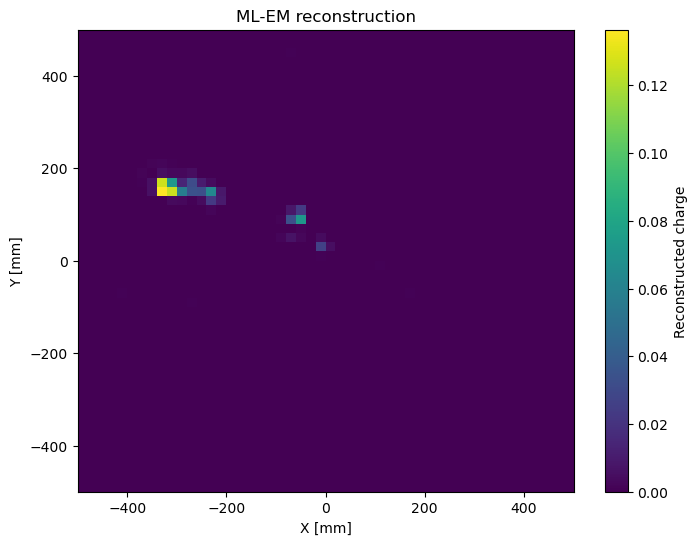

Sum of guess: 1.000000, NaN count: 0, Max value: 3.903762e-02


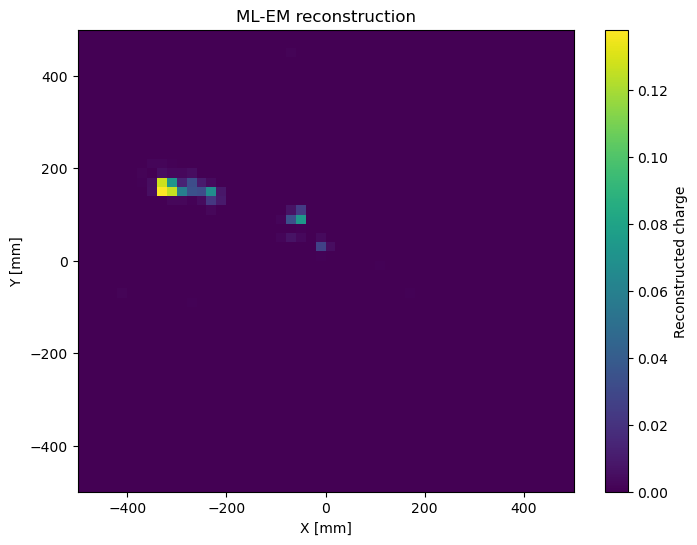

Sum of guess: 1.000000, NaN count: 0, Max value: 3.988078e-02


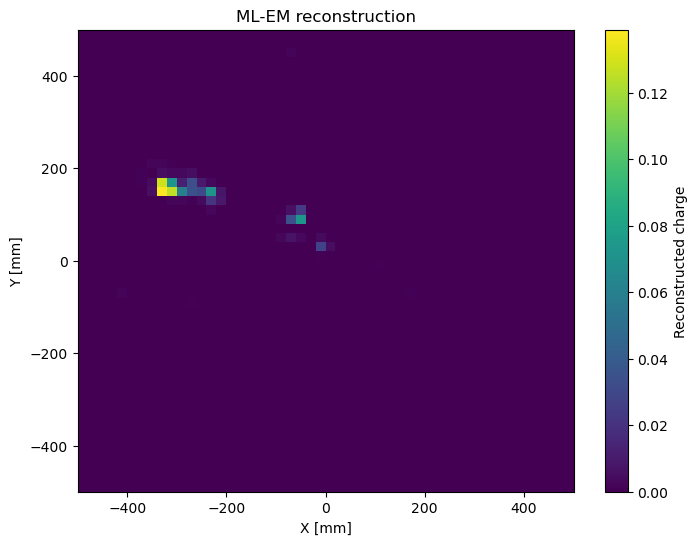

Sum of guess: 1.000000, NaN count: 0, Max value: 4.026338e-02


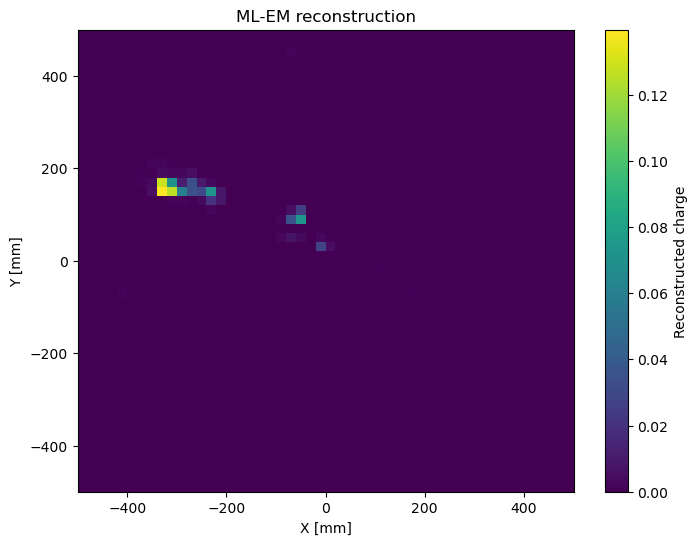

Sum of guess: 1.000000, NaN count: 0, Max value: 4.046340e-02


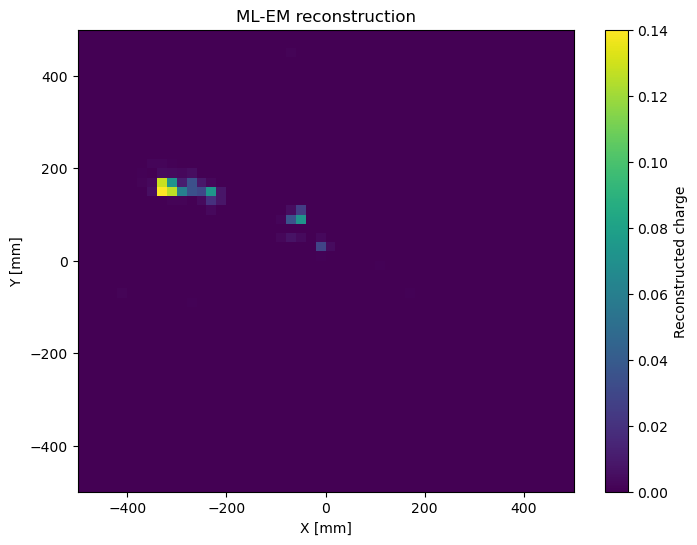

Sum of guess: 1.000000, NaN count: 0, Max value: 4.058268e-02


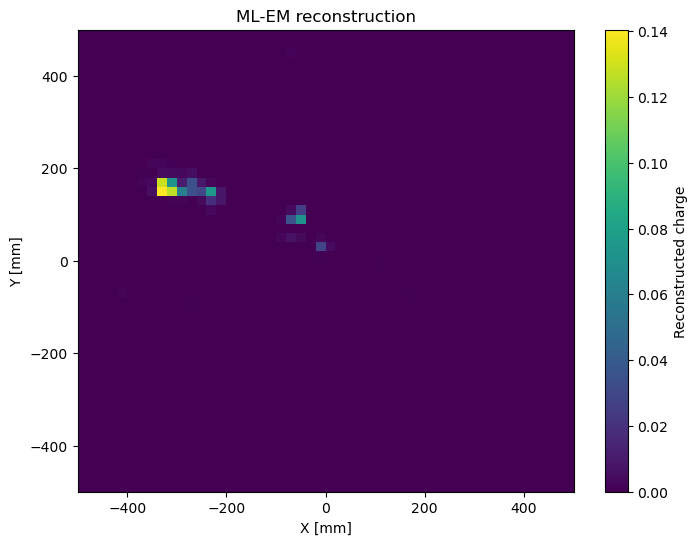

In [ ]:
for g in guesses:
    print(f"Sum of guess: {g.sum():.6f}, NaN count: {np.isnan(g).sum()}, Max value: {g.max():.6e}")
    plt.figure(figsize=(8, 6))
    plt.hist2d(
        bin_x,
        bin_y,
        bins=50,
        weights=g,
        range=((-500, 500), (-500, 500)),
        cmap="viridis"
    )
    plt.title("ML-EM reconstruction")
    plt.xlabel("X [mm]")
    plt.ylabel("Y [mm]")
    plt.colorbar(label="Reconstructed charge")
    plt.show()